This notebook prepares the data. The actual fine-tuning happens in later lessons.

Python, Hugging Face, tokenization, data preparation, and plotting


We have product descriptions and prices. We are preparing examples so Llama 3.2 3B can learn to predict a price from a description.

In [1]:
import os
from dotenv import load_dotenv
from huggingface_hub import login
from pricer.items import Item
from tqdm.notebook import tqdm
from transformers import AutoTokenizer
import matplotlib.pyplot as plt

This is not a standard Python library. It comes from the price.

It helps manage product examples, including:
- Product summary
- Price
- Prompt
- Completion
- Token counting
- Dataset loading and saving


Think of Item as a ready-made tool for handling each product.

### Selecting the dataset and logging in

In [2]:
# True → Use the smaller/light dataset.
# False → Use the full dataset.
LITE_MODE = False

In [3]:
## logging in

load_dotenv(override=True)
hf_token = os.environ["HF_TOKEN"]
login(hf_token, add_to_git_credential=True)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Loading the dataset

In [4]:
username = "ed-donner"

dataset = (
    f"{username}/items_lite"
    if LITE_MODE
    else f"{username}/items_full"
)

train, val, test = Item.from_hub(dataset)

items = train + val + test

print(
    f"Loaded {len(train):,} training items, "
    f"{len(val):,} validation items, "
    f"{len(test):,} test items"
)

Loaded 800,000 training items, 10,000 validation items, 10,000 test items


### Loading the tokenizer

In [5]:
BASE_MODEL = "meta-llama/Llama-3.2-3B"
# loads the tokenizer associated with that model.
# We need the tokenizer to determine how long each description is before training.
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

### Counting tokens in each product

In [6]:
# Create an empty list to store the token counts of all product summaries

token_counts = []

# Loop through each product in the dataset and display a progress bar
for item in tqdm(items):

    # Convert the product summary into token IDs using the tokenizer
    # Add special tokens if required by the tokenizer
    tokens = tokenizer.encode(
        item.summary,
        add_special_tokens=True
    )
    # Count the number of tokens and append the count to the list
    token_counts.append(len((tokens)))

  0%|          | 0/820000 [00:00<?, ?it/s]

### Visualizing token lengths

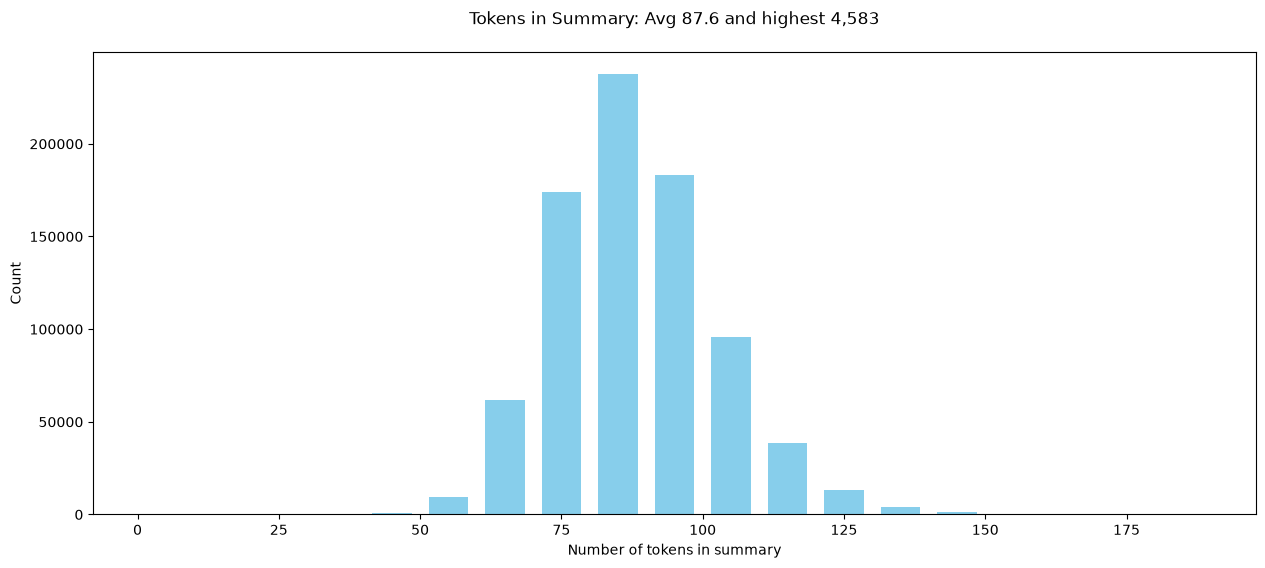

In [7]:
plt.figure(figsize=(15, 6))

plt.title(
    f"Tokens in Summary: Avg "
    f"{sum(token_counts)/len(token_counts):,.1f} "
    f"and highest {max(token_counts):,}\n"
)

plt.xlabel('Number of tokens in summary')
plt.ylabel('Count')

plt.hist(
    token_counts,
    rwidth=0.7,
    color="skyblue",
    bins=range(0, 200, 10)
)

plt.show()

Conclusion: The histogram shows that most product summaries contain approximately 75–100 tokens, with an average of 87.6 tokens. However, some summaries are much longer, with the maximum reaching 4,583 tokens. Therefore, choosing a cutoff of 110 tokens can reduce memory usage and improve training efficiency, while truncating some longer descriptions and potentially losing information.

In [8]:
# We allow up to 110 tokens in each summary.
CUTTOFF = 110

# This selects token counts greater than 110.
# Counts how many descriptions exceed the cutoff and save in cut.
cut = len([count for count in token_counts if count > CUTTOFF])
# len() tells how many number of products has above 110 tokens in description.

In [9]:
cut

52408

In [10]:
print(
    f"With this CUTOFF, we will truncate "
    f"{cut:,} items which is {cut/len(items):.1%}"
)

With this CUTOFF, we will truncate 52,408 items which is 6.4%


In [ ]:
print(train[0].summary)

### Creating prompts and completions

What does make_prompts() do internally?
Based on the lecture, its logic is roughly:
1. Get the summary.
2. Tokenize it.
3. If it exceeds 110 tokens, truncate it.
4. Decode the resulting tokens into text.
5. Construct the prompt.
6. Prepare the completion from the target price, with the appropriate rounding behavior

The purpose of make_prompt() and make_prompts() is to prepare the raw dataset into a format suitable for our model. This is called data preprocessing / dataset preparation.

In [12]:
for item in tqdm(train+val):
    item.make_prompts(tokenizer, CUTTOFF, True)
for item in tqdm(test):
    item.make_prompts(tokenizer, CUTTOFF, False)

  0%|          | 0/810000 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


  0%|          | 0/10000 [00:00<?, ?it/s]

In [16]:
print("PROMPT:")
print(test[0].prompt)

# The completion contains the target price that the model should learn to generate.
print("COMPLETION:")
print(test[0].completion)

PROMPT:
What does this cost to the nearest dollar?

Title: Excess V2 Distortion/Modulation Pedal  
Category: Music Pedals  
Brand: Old Blood Noise  
Description: A versatile pedal offering distortion and three modulation modes—delay, chorus, and harmonized fifths—with full control over signal routing and expression.  
Details: Features include separate gain, tone, and volume controls; time, depth, and volume per modulation; order switching, soft‑touch bypass, and expression jack for dynamic control.

Price is $
COMPLETION:
219.0


### Counting tokens after prompt preparation

In [17]:
prompt_token_counts = []

for item in tqdm(items):
    counts = item.count_prompt_tokens(tokenizer)

    prompt_token_counts.append(counts)

  0%|          | 0/820000 [00:00<?, ?it/s]

### Plotting the final token counts

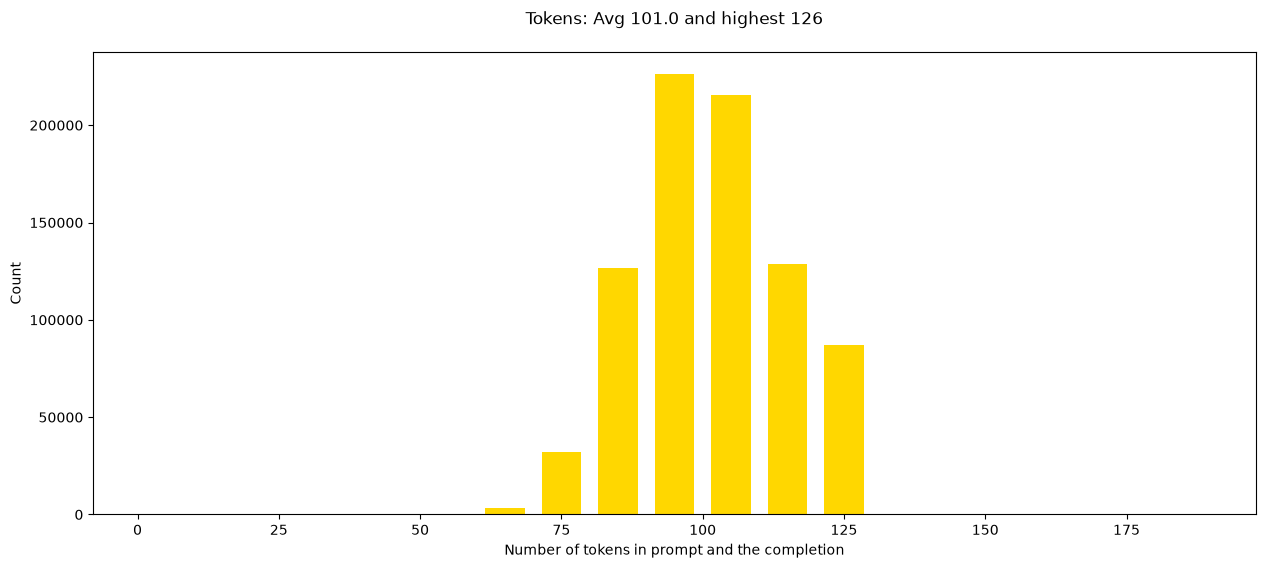

In [18]:
plt.figure(figsize=(15, 6))

plt.title(
    f"Tokens: Avg "
    f"{sum(prompt_token_counts)/len(prompt_token_counts):,.1f} "
    f"and highest {max(prompt_token_counts):,}\n"
)

plt.xlabel('Number of tokens in prompt and the completion')
plt.ylabel('Count')

plt.hist(
    prompt_token_counts,
    rwidth=0.7,
    color="gold",
    bins=range(0, 200, 10)
)

plt.show()

X-axis: Number of tokens in the prompt + completion.

Y-axis (Count): How many product examples have that token length.

The histogram shows that the average prompt and completion length is 101 tokens, with a maximum of 126 tokens.
- Most examples contain approximately 90–110 tokens.

### Uploading the prepared dataset to Hugging Face

In [19]:
username = "riazhumaima"

dataset = (
    f"{username}/items_prompts_lite"
    if LITE_MODE
    else f"{username}/items_prompts_full"
)

Item.push_prompts_to_hub(dataset, train, val, test)

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Creating parquet from Arrow format:   0%|          | 0/800 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

...

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Creating parquet from Arrow format:   0%|          | 0/10 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            